In [3]:
import numpy as np
import scipy.io as scio
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
from importlib import reload
import my_BLS_Regression_5
reload(my_BLS_Regression_5)
from my_BLS_Regression_5 import BLS_regression

In [7]:
np.random.seed(77)
data = np.random.standard_normal((100, 3))
data.shape

(100, 3)

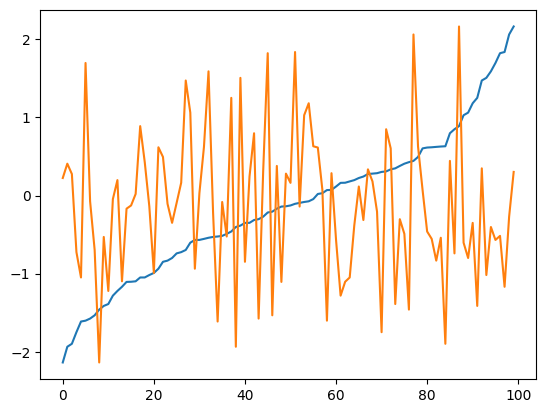

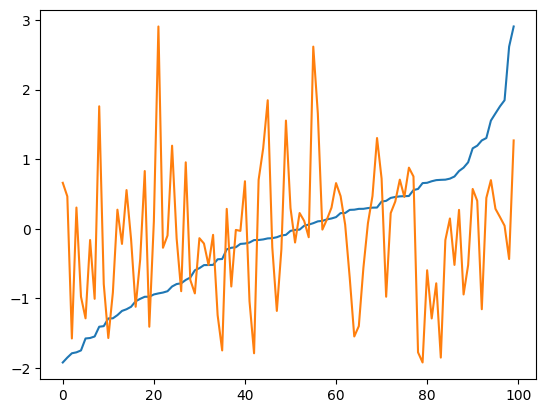

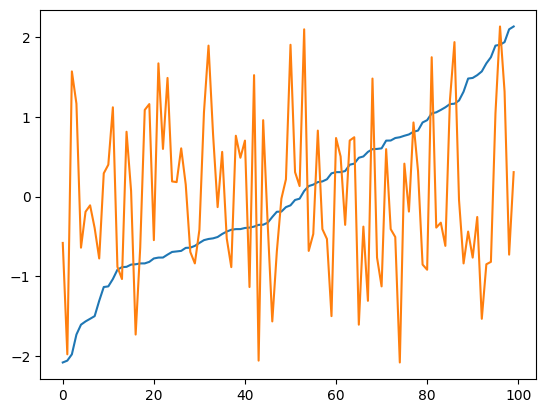

In [ ]:
for i in range(3):
    plt.plot(np.sort(data[:,i]))
    plt.plot(data[:,i])
    plt.show();

In [21]:
target = 3*(data[:,0]**3) + 0.5*(data[:,1]) + (4/7) * np.sin(data[:,2])
target.shape

(100,)

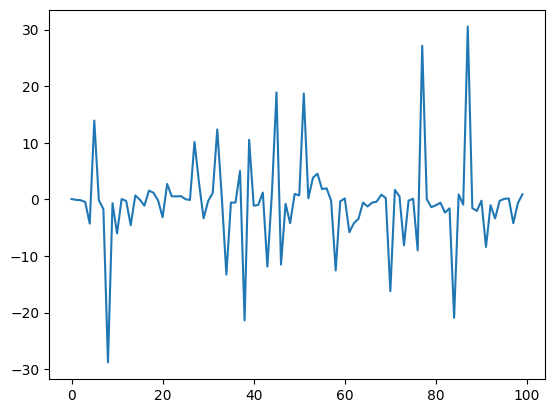

In [22]:
plt.plot(target)

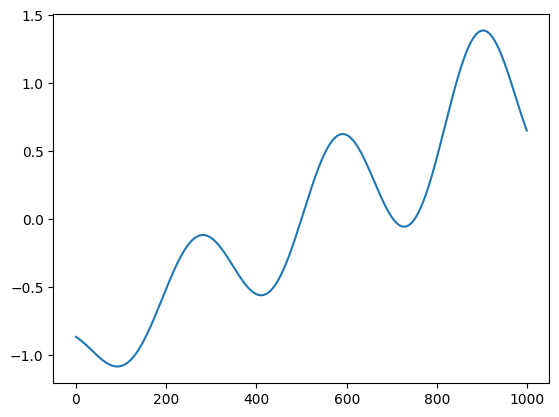

In [56]:
data_lin1 = np.linspace(-10, 10, 1000)
data_lin2 = np.linspace(0.5, 0.8, 1000)
data_lin3 = np.linspace(-1, 1, 1000)
target_lin = (data_lin2**2) * np.sin(data_lin1) + data_lin3
plt.plot(target_lin)

In [107]:
data_ar = np.vstack([data_lin1, data_lin2, data_lin3, target_lin]).T
data_ar[0]

array([-10.        ,   0.5       ,  -1.        ,  -0.86399472])

In [111]:
index_permute = np.random.permutation(1000)

In [ ]:
train1 = data_ar[index_permute[:750], :]
test1 = data_ar[index_permute[750:1000], :]

In [121]:
data_splitted = [data_ar[index_permute[:200],:], data_ar[index_permute[200:400],:], data_ar[index_permute[400:600],:], data_ar[index_permute[600:800],:], data_ar[index_permute[800:1000],:]]

fold = []

train1 = np.vstack([data_splitted[1], data_splitted[2], data_splitted[3], data_splitted[4]])
test1 = data_splitted[0]
fold.append([train1, test1])

train2 = np.vstack([data_splitted[0], data_splitted[2], data_splitted[3], data_splitted[4]])
test2 = data_splitted[1]
fold.append([train2, test2])

train3 = np.vstack([data_splitted[0], data_splitted[1], data_splitted[3], data_splitted[4]])
test3 = data_splitted[2]
fold.append([train3, test3])

train4 = np.vstack([data_splitted[0], data_splitted[1], data_splitted[2], data_splitted[4]])
test4 = data_splitted[3]
fold.append([train4, test4])

train5 = np.vstack([data_splitted[1], data_splitted[2], data_splitted[3], data_splitted[0]])
test5 = data_splitted[4]
fold.append([train5, test5])


In [127]:
fold[1][1].shape, fold[1][0].shape

((200, 4), (800, 4))

In [142]:
results = []
n_features_list = range(1, 15)
n_ftr_groups_list = range(1, 15)
n_enhancements_list = range(0, 15)
n_enh_groups_list = range(1, 15)

for n_features in n_features_list:
    for n_ftr_groups in n_ftr_groups_list:
        for n_enhancements in n_enhancements_list:
            for n_enh_groups in n_enh_groups_list:
                fit_RMSE_sum, fit_MAPE_sum, pred_RMSE_sum, pred_MAPE_sum = 0, 0, 0, 0

                for traintest in fold:
                    
                    model = BLS_regression(0.001, 0.001, n_features, n_ftr_groups, n_enhancements, n_enh_groups, activation='relu6')
                    model.fit(traintest[0][:,:3], traintest[0][:,3])
                    model.predict(traintest[1][:,:3], traintest[1][:,3])
                    fit_RMSE_sum += model.fit_RMSE
                    fit_MAPE_sum += model.fit_MAPE
                    pred_RMSE_sum += model.pred_RMSE
                    pred_MAPE_sum += model.pred_MAPE

                
                results.append([n_features, n_ftr_groups, n_enhancements, n_enh_groups, fit_RMSE_sum / 5, pred_RMSE_sum / 5, fit_MAPE_sum / 5, pred_MAPE_sum / 5])
                

# pd.DataFrame(results, columns=['n_features', 'n_windows', 'n_enhancements', 'fit0_RMSE', 'pred0_RMSE']).to_csv('scenario')
results_df = pd.DataFrame(results, columns=['n_features', 'n_ftr_groups', 'n_enhancements', 'n_enh_groups', 'fit_RMSE', 'pred_RMSE', 'fit_MAPE', 'pred_MAPE'])
results_df.head()



,n_features,n_ftr_groups,n_enhancements,n_enh_groups,fit_RMSE,pred_RMSE,fit_MAPE,pred_MAPE
0,1,1,0,1,0.299683,0.300437,3.638769,3.675556
1,1,1,0,2,0.299683,0.300437,3.638769,3.675556
2,1,1,0,3,0.299683,0.300437,3.638769,3.675556
3,1,1,0,4,0.299683,0.300437,3.638769,3.675556
4,1,1,0,5,0.299683,0.300437,3.638769,3.675556


In [147]:
pd.DataFrame(results, columns=['n_features', 'n_ftr_groups', 'n_enhancements', 'n_enh_groups', 'fit_RMSE', 'pred_RMSE', 'fit_MAPE', 'pred_MAPE']).to_csv('manyModelsKfold.csv')


<Figure size 1200x400 with 0 Axes>

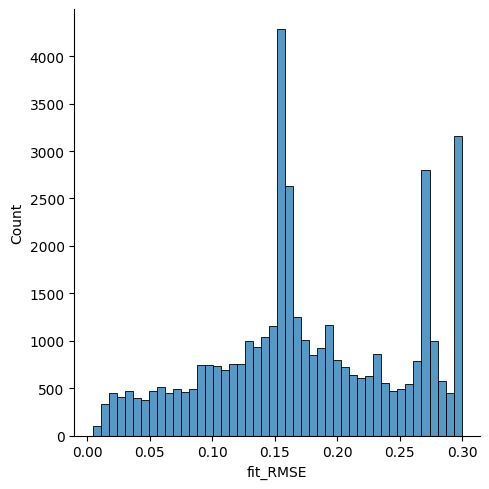

In [143]:
plt.figure(figsize=(12,4))
sns.displot(results_df['fit_RMSE'])

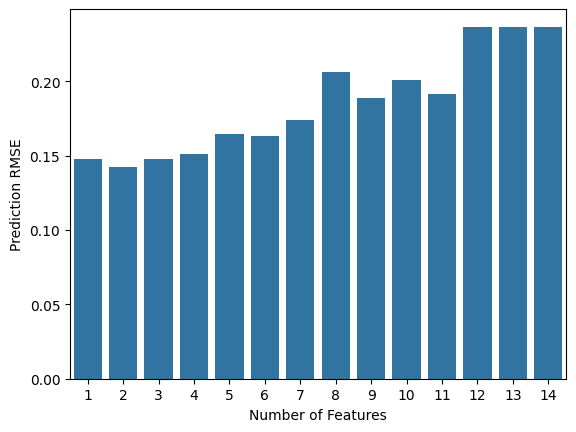

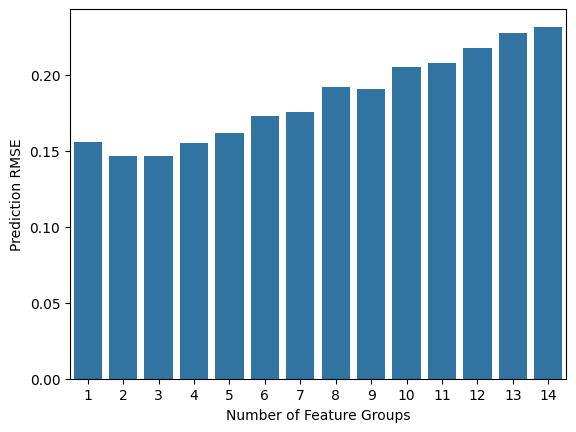

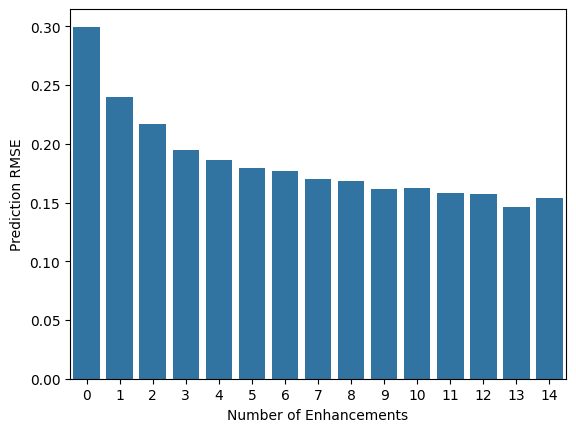

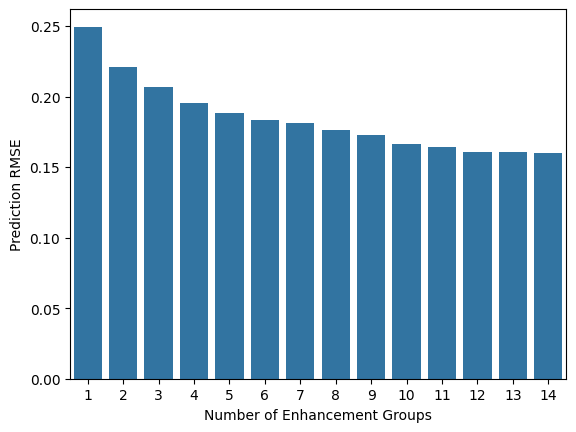

,1,2,3,4,5,6,7,8,9,10,11,12,13,14
features . predict RMSE,0.147946,0.142128,0.147641,0.151354,0.164538,0.162828,0.173813,0.206169,0.188867,0.200475,0.191483,0.236305,0.236597,0.236349
feature groups . predict RMSE,0.155948,0.146483,0.146340,0.155099,0.161882,0.173099,0.175569,0.192212,0.190439,0.204960,0.207507,0.217777,0.227592,0.231587
enhancements . predict RMSE,0.239977,0.216595,0.194361,0.186063,0.179096,0.176840,0.170040,0.168736,0.161558,0.162669,0.158415,0.157052,0.146454,0.153721
enhancement groups . predict RMSE,0.221188,0.206948,0.195574,0.187985,0.183457,0.181037,0.176236,0.172551,0.166648,0.164133,0.160712,0.160947,0.159626,NaN


In [144]:
rslt1, rslt2, rslt3, rslt4 = [], [], [], []
for i in n_features_list:
    rslt1.append(results_df.loc[results_df.loc[: ,'n_features'] == i].loc[:,'pred_RMSE'].mean())
sns.barplot(rslt1)
plt.ylabel('Prediction RMSE')
plt.xticks(ticks=range(len(n_features_list)),labels=n_features_list)
plt.xlabel('Number of Features')
plt.show()

for i in n_ftr_groups_list:
    rslt2.append(results_df.loc[results_df.loc[: ,'n_ftr_groups'] == i].loc[:,'pred_RMSE'].mean())
sns.barplot(rslt2)
plt.ylabel('Prediction RMSE')
plt.xticks(ticks=range(len(n_ftr_groups_list)),labels=n_ftr_groups_list)
plt.xlabel('Number of Feature Groups')
plt.show()

for i in n_enhancements_list:
    rslt3.append(results_df.loc[results_df.loc[: ,'n_enhancements'] == i].loc[:,'pred_RMSE'].mean())
sns.barplot(rslt3)
plt.ylabel('Prediction RMSE')
plt.xticks(ticks=range(len(n_enhancements_list)),labels=n_enhancements_list)
plt.xlabel('Number of Enhancements')
plt.show()

for i in n_enh_groups_list:
    if i != 0:
        rslt4.append(results_df.loc[results_df.loc[: ,'n_enh_groups'] == i].loc[:,'pred_RMSE'].mean())
sns.barplot(rslt4)
plt.ylabel('Prediction RMSE')
plt.xticks(ticks=range(len(n_enh_groups_list)),labels=n_enh_groups_list)
plt.xlabel('Number of Enhancement Groups')
plt.show()

test = pd.DataFrame([rslt1, rslt2, rslt3[1:], rslt4[1:]], columns=n_features_list, index=['features . predict RMSE', 'feature groups . predict RMSE', 'enhancements . predict RMSE', 'enhancement groups . predict RMSE'])
# test.to_csv('big grid search 2.csv')
test

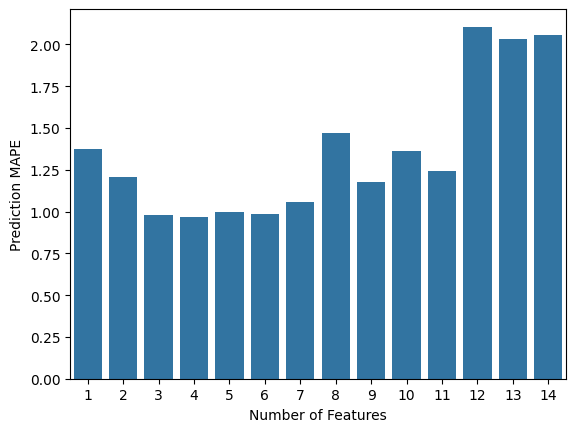

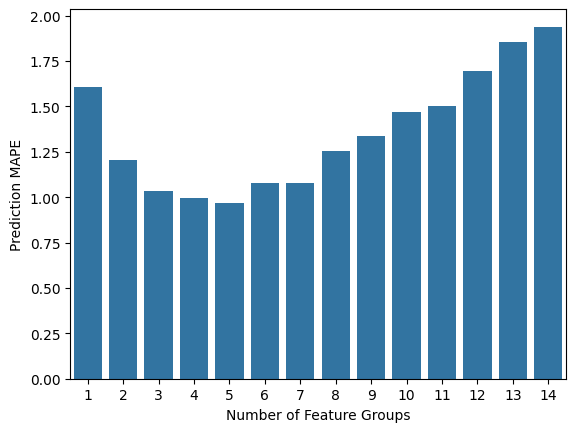

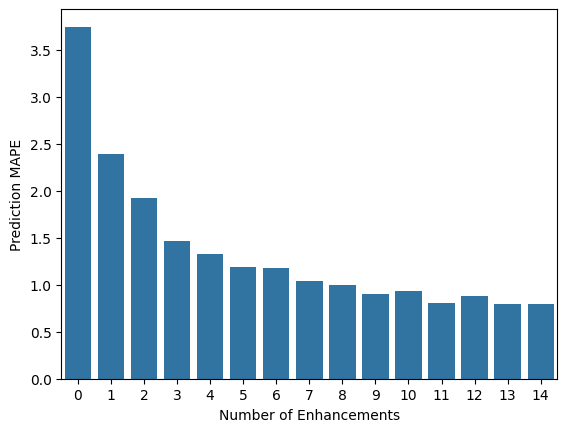

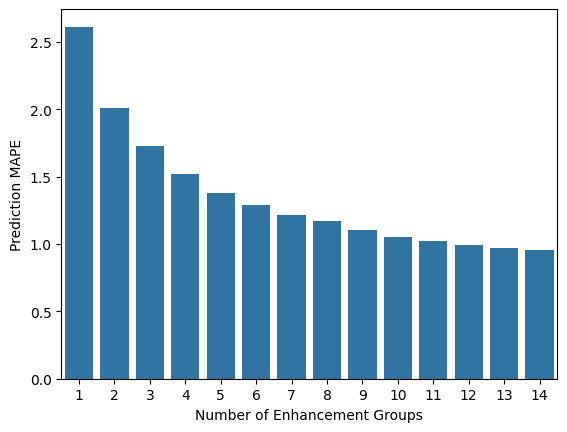

,1,2,3,4,5,6,7,8,9,10,11,12,13,14
features . predict RMSE,1.372686,1.205059,0.982591,0.966826,0.997341,0.982835,1.060385,1.468296,1.179067,1.362485,1.245072,2.106266,2.034235,2.056413
feature groups . predict RMSE,1.605133,1.204860,1.035417,0.998019,0.966976,1.078195,1.077506,1.256019,1.339072,1.469374,1.501941,1.694852,1.853663,1.938530
enhancements . predict RMSE,2.391370,1.926591,1.466065,1.324177,1.191691,1.178226,1.039710,1.001913,0.902577,0.932736,0.805144,0.878180,0.797104,0.794605
enhancement groups . predict RMSE,2.006632,1.729473,1.522848,1.381635,1.286706,1.215280,1.168668,1.105779,1.051078,1.022317,0.992270,0.970411,0.953148,NaN


In [148]:
rslt1, rslt2, rslt3, rslt4 = [], [], [], []
for i in n_features_list:
    rslt1.append(results_df.loc[results_df.loc[: ,'n_features'] == i].loc[:,'pred_MAPE'].mean())
sns.barplot(rslt1)
plt.ylabel('Prediction MAPE')
plt.xticks(ticks=range(len(n_features_list)),labels=n_features_list)
plt.xlabel('Number of Features')
plt.show()

for i in n_ftr_groups_list:
    rslt2.append(results_df.loc[results_df.loc[: ,'n_ftr_groups'] == i].loc[:,'pred_MAPE'].mean())
sns.barplot(rslt2)
plt.ylabel('Prediction MAPE')
plt.xticks(ticks=range(len(n_ftr_groups_list)),labels=n_ftr_groups_list)
plt.xlabel('Number of Feature Groups')
plt.show()

for i in n_enhancements_list:
    rslt3.append(results_df.loc[results_df.loc[: ,'n_enhancements'] == i].loc[:,'pred_MAPE'].mean())
sns.barplot(rslt3)
plt.ylabel('Prediction MAPE')
plt.xticks(ticks=range(len(n_enhancements_list)),labels=n_enhancements_list)
plt.xlabel('Number of Enhancements')
plt.show()

for i in n_enh_groups_list:
    if i != 0:
        rslt4.append(results_df.loc[results_df.loc[: ,'n_enh_groups'] == i].loc[:,'pred_MAPE'].mean())
sns.barplot(rslt4)
plt.ylabel('Prediction MAPE')
plt.xticks(ticks=range(len(n_enh_groups_list)),labels=n_enh_groups_list)
plt.xlabel('Number of Enhancement Groups')
plt.show()

test = pd.DataFrame([rslt1, rslt2, rslt3[1:], rslt4[1:]], columns=n_features_list, index=['features . predict RMSE', 'feature groups . predict RMSE', 'enhancements . predict RMSE', 'enhancement groups . predict RMSE'])
# test.to_csv('big grid search 2.csv')
test

In [166]:
result_list = []

for traintest in fold:          
    chosen_model = BLS_regression(0.001, 0.001, 4, 5, 11, 14, activation='relu6')

    chosen_model.fit(traintest[0][:,:3], traintest[0][:,3])
    chosen_model.predict(traintest[1][:,:3], traintest[1][:,3])
    result_list.append([chosen_model.fit_RMSE, chosen_model.fit_MAPE*100, chosen_model.pred_RMSE, chosen_model.pred_MAPE*100])

result = pd.DataFrame(result_list, columns=['fit RMSE', 'fit MAPE', 'predict RMSE', 'predict MAPE'])
# result.to_csv('chosenKFold.csv')
result


,fit RMSE,fit MAPE,predict RMSE,predict MAPE
0,0.050406,9.776680,0.045666,7.811410
1,0.028582,5.706005,0.030113,6.120935
2,0.053393,11.627341,0.047055,7.974289
3,0.030810,5.696253,0.042988,7.162479
4,0.023138,5.519561,0.026140,5.946683


In [168]:
predicts = chosen_model.predict(data_ar[:,:3], data_ar[:,3])
len(predicts)

1000

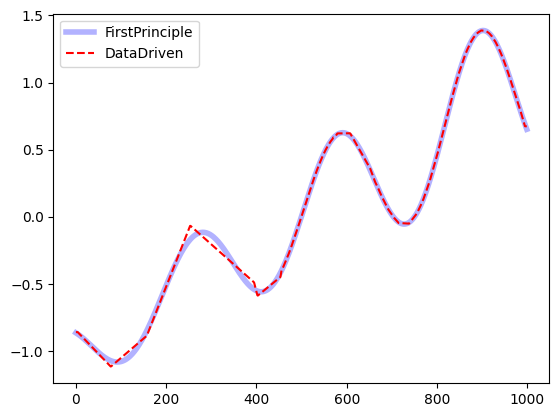

In [190]:
plt.plot(data_ar[:,3], color='blue', alpha=0.3, linewidth=4, label='FirstPrinciple')
plt.plot(predicts, color='red', linestyle='--', label='DataDriven')
plt.legend()
plt.show()